## Predicting price of used cars

Importing the datasets

In [101]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [102]:
df=pd.read_csv('https://raw.githubusercontent.com/sahilrahman12/Price_prediction_of_used_Cars_-Predictive_Analysis-/master/car_data.csv')

In [103]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [104]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [105]:
print(df.fuel.unique())
print(df.seller_type.unique())
print(df.transmission.unique())
print(df.owner.unique())

['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
['Individual' 'Dealer' 'Trustmark Dealer']
['Manual' 'Automatic']
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


In [106]:
df.drop(['name'],axis=1,inplace=True)

OneHot Encoding

In [107]:
df=pd.get_dummies(df,dtype=float)

In [108]:
df.head()

,year,selling_price,km_driven,fuel_CNG,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Automatic,transmission_Manual,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2007,60000,70000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,2007,135000,50000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,2012,600000,100000,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,2017,250000,46000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,2014,450000,141000,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [109]:
df['no_of_year']=2021-df.year
df.drop(['year'],axis=1,inplace=True)

In [110]:
df.head()

,selling_price,km_driven,fuel_CNG,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Automatic,transmission_Manual,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,no_of_year
0,60000,70000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,14
1,135000,50000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,14
2,600000,100000,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,9
3,250000,46000,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,4
4,450000,141000,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,7


In [111]:
df.shape

(4340, 18)

In [112]:
df.columns

Index(['selling_price', 'km_driven', 'fuel_CNG', 'fuel_Diesel',
       'fuel_Electric', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Dealer',
       'seller_type_Individual', 'seller_type_Trustmark Dealer',
       'transmission_Automatic', 'transmission_Manual', 'owner_First Owner',
       'owner_Fourth & Above Owner', 'owner_Second Owner',
       'owner_Test Drive Car', 'owner_Third Owner', 'no_of_year'],
      dtype='object')

In [113]:
df.drop(columns=['fuel_CNG','seller_type_Dealer','transmission_Automatic','owner_First Owner'],inplace=True)

In [114]:
df.head()

,selling_price,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,no_of_year
0,60000,70000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,14
1,135000,50000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,14
2,600000,100000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,9
3,250000,46000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4
4,450000,141000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,7


In [115]:
df.shape

(4340, 14)

In [116]:
df.corr()

,selling_price,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,no_of_year
selling_price,1.000000,-0.192289,0.282947,-0.005095,-0.042434,-0.269453,-0.236798,0.110176,-0.530205,-0.078725,-0.161986,0.048799,-0.111326,-0.413922
km_driven,-0.192289,1.000000,0.285396,-0.001372,0.036652,-0.291139,0.182663,-0.089858,0.120226,0.097349,0.195203,-0.083445,0.194713,0.419688
fuel_Diesel,0.282947,0.285396,1.000000,-0.015063,-0.072422,-0.970934,-0.035314,-0.007911,-0.048098,-0.021054,0.003524,-0.010575,0.009373,-0.121424
fuel_Electric,-0.005095,-0.001372,-0.015063,1.000000,-0.001108,-0.014856,-0.026118,-0.002355,-0.044746,-0.002094,0.025960,-0.000952,-0.004166,0.025540
fuel_LPG,-0.042434,0.036652,-0.072422,-0.001108,1.000000,-0.071427,0.035122,-0.011324,0.024764,0.013384,0.030141,-0.004577,0.004836,0.051266
fuel_Petrol,-0.269453,-0.291139,-0.970934,-0.014856,-0.071427,1.000000,0.029845,0.012489,0.039614,0.011502,-0.012717,0.012427,-0.008502,0.114908
seller_type_Individual,-0.236798,0.182663,-0.035314,-0.026118,0.035122,0.029845,1.000000,-0.266904,0.214163,0.072322,0.186573,-0.107886,0.140823,0.173703
seller_type_Trustmark Dealer,0.110176,-0.089858,-0.007911,-0.002355,-0.011324,0.012489,-0.266904,1.000000,-0.042346,-0.021395,-0.076764,-0.009729,-0.042578,-0.100225
transmission_Manual,-0.530205,0.120226,-0.048098,-0.044746,0.024764,0.039614,0.214163,-0.042346,1.000000,0.035597,0.068068,0.009152,0.030802,0.143800
owner_Fourth & Above Owner,-0.078725,0.097349,-0.021054,-0.002094,0.013384,0.011502,0.072322,-0.021395,0.035597,1.000000,-0.080648,-0.008648,-0.037849,0.186361


<Axes: >

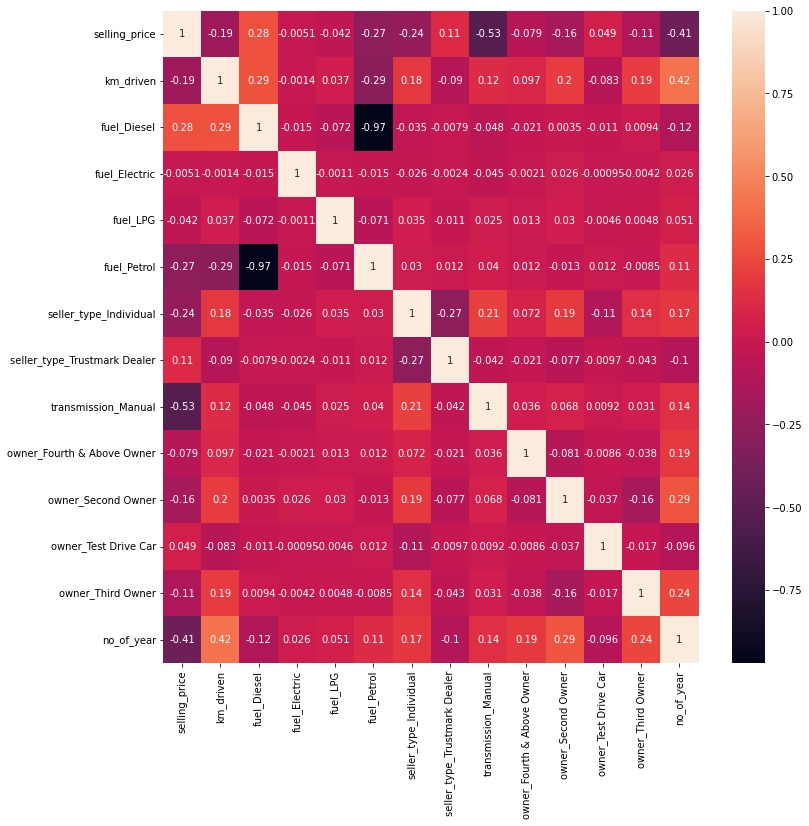

In [117]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(),annot=True,color='red')

In [118]:
df.head()

,selling_price,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,no_of_year
0,60000,70000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,14
1,135000,50000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,14
2,600000,100000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,9
3,250000,46000,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,4
4,450000,141000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,7


Machine Learning

In [119]:
X=np.array(df.drop(['selling_price'],axis=1))
Y=np.array(df.selling_price).reshape(-1,1)

Feature Selection(Feature Importance)

In [120]:
from sklearn.ensemble import ExtraTreesRegressor

In [121]:
model=ExtraTreesRegressor()

In [122]:
feat_imp=model.fit(X,Y)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [123]:
imp=pd.Series(feat_imp.feature_importances_,index=((df.drop(['selling_price'],axis=1).columns)))

<Axes: >

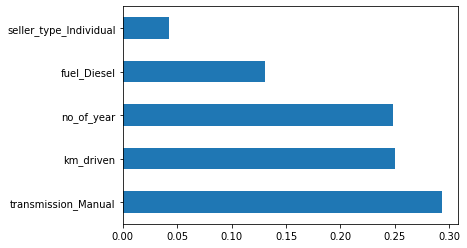

In [124]:
imp.nlargest(5).plot(kind='barh')

In [125]:
imp.nlargest(len(imp))*100

transmission_Manual             29.282746
km_driven                       25.038019
no_of_year                      24.818936
fuel_Diesel                     13.026553
seller_type_Individual           4.226188
owner_Second Owner               2.174317
seller_type_Trustmark Dealer     0.829379
owner_Third Owner                0.408200
owner_Test Drive Car             0.099989
owner_Fourth & Above Owner       0.066952
fuel_Petrol                      0.022790
fuel_Electric                    0.003257
fuel_LPG                         0.002675
dtype: float64

Splitting the data

In [126]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=0,shuffle=True)

In [127]:
pd.DataFrame(X_train,columns=((df.drop(['selling_price'],axis=1).columns)))

,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,no_of_year
0,175000.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0
1,170000.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,9.0
2,110000.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,15.0
3,66521.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,6.0
4,41000.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3467,58500.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0
3468,110000.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,9.0
3469,22000.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,5.0
3470,70000.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0


Model Selection

In [128]:
regressor=RandomForestRegressor()

Hyperparameter Tuning

Parameters:
- n_estimators: Int = 100
- criterion: Literal['squared_error', 'absolute_error', 'friedman_mse', 'poisson'] = "squared_error"
- max_depth: Int | None = None
- min_samples_split: float | int = 2
- min_samples_leaf: float | int = 1 
- min_weight_fraction_leaf: Float = 0
- max_features: float | int | Literal['sqrt', 'log2'] = 1 
- max_leaf_nodes: Int | None = None 
- min_impurity_decrease: Float = 0
- bootstrap: bool = True
- oob_score: bool = False
- n_jobs: Int | None = None
- random_state: Int | RandomState | None = None
- verbose: Int = 0
- warm_start: bool = False
- ccp_alpha: float = 0
- max_samples: float | int | None = None


In [129]:
n_estimators=[int(i) for i in np.linspace(start=100,stop=1200,num=12)]

max_features=['auto','sqrt','log2']

max_depth=[int(x) for x in np.linspace(start=5,stop=30,num=6)]

min_samples_split=[1,2,5,10,25,100]

min_samples_leaf=[2,5,10,25]


In [130]:
random_grid={'n_estimators':n_estimators,
             'max_features':max_features,
             'max_depth':max_depth,
             'min_samples_split':min_samples_split,
             'min_samples_leaf':min_samples_leaf}

In [131]:
random_grid

{'n_estimators': [100,
  200,
  300,
  400,
  500,
  600,
  700,
  800,
  900,
  1000,
  1100,
  1200],
 'max_features': ['auto', 'sqrt', 'log2'],
 'max_depth': [5, 10, 15, 20, 25, 30],
 'min_samples_split': [1, 2, 5, 10, 25, 100],
 'min_samples_leaf': [2, 5, 10, 25]}

In [132]:
from sklearn.model_selection import RandomizedSearchCV

In [133]:
rf_regressor=RandomizedSearchCV(estimator=regressor,
                                param_distributions=random_grid,
                                scoring='neg_mean_squared_error', #can use r2_score/mse/mae also
                                cv=5, #gotta learn in classification
                                verbose=2,
                                random_state=42,
                                n_jobs=1) 


In [134]:
rf_regressor.fit(X_train,Y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END max_depth=5, max_features=log2, min_samples_leaf=25, min_samples_split=100, n_estimators=900; total time=   1.0s


c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END max_depth=5, max_features=log2, min_samples_leaf=25, min_samples_split=100, n_estimators=900; total time=   0.9s


c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


... (57 outputs left out)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


[CV] END max_depth=10, max_features=log2, min_samples_leaf=25, min_samples_split=5, n_estimators=600; total time=   0.7s


c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
15 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py", line 729, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py", line 1145, in wrapper
    estimator._validate_params()
  File "c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py

RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(), n_jobs=1,
                   param_distributions={'max_depth': [5, 10, 15, 20, 25, 30],
                                        'max_features': ['auto', 'sqrt',
                                                         'log2'],
                                        'min_samples_leaf': [2, 5, 10, 25],
                                        'min_samples_split': [1, 2, 5, 10, 25,
                                                              100],
                                        'n_estimators': [100, 200, 300, 400,
                                                         500, 600, 700, 800,
                                                         900, 1000, 1100,
                                                         1200]},
                   random_state=42, scoring='neg_mean_squared_error',
                   verbose=2)

In [135]:
rf_regressor.best_params_

{'n_estimators': 500,
 'min_samples_split': 5,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': 25}

Predicting the model

In [136]:
Y_pred=rf_regressor.predict(X_test) 

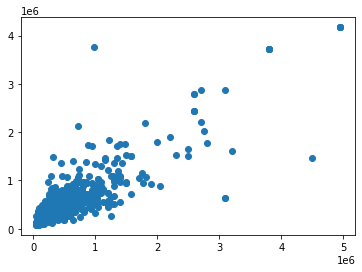

In [137]:
plt.scatter(Y_test,Y_pred)

In [138]:
Y_test=Y_test.reshape(-1)

In [139]:
finaldf_hyper=pd.DataFrame({'Actual':Y_test,'Predicted':Y_pred})

<Axes: >

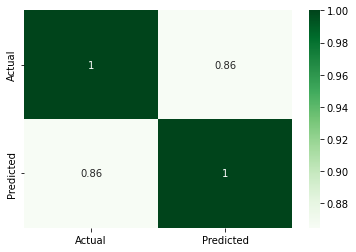

In [140]:
sns.heatmap(finaldf_hyper.corr(),annot=True,cmap='Greens')

In [141]:
regressor.fit(X_train,Y_train)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor()

In [142]:
Y_pred2=regressor.predict(X_test)

In [143]:
finaldf_no_hyper=pd.DataFrame({'Actual':Y_test,'Predicted':Y_pred2})

<Axes: >

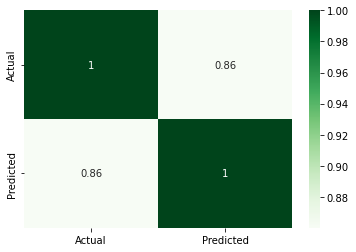

In [144]:
sns.heatmap(finaldf_no_hyper.corr(),annot=True,cmap='Greens')

In [145]:
r2_score(Y_test,Y_pred)

0.7474089619117237

In [146]:
r2_score(Y_test,Y_pred2)

0.7253000388611605

In [147]:
mean_absolute_error(Y_test,Y_pred)

168812.93150377698

In [148]:
mean_absolute_error(Y_test,Y_pred2)

161014.07684011332

In [149]:
np.sqrt(mean_squared_error(Y_test,Y_pred))

306267.83342949464

In [150]:
np.sqrt(mean_squared_error(Y_test,Y_pred2))

319390.29565650434